# Mini-Project 1: Fetching and Displaying a Weather Forecast

**What this notebook does.** Takes a location name, finds its coordinates,
requests a forecast from Open-Meteo, cross-checks it against MET Norway, and
displays the result as a table, a summary and a chart.

**Where the code lives.** Everything reusable is in `src/weather/`:
`http.py` (the retrying client), `sources.py` (the two providers and the
`geocode` / `get_forecast` functions), `wmo.py` (weather-code decoding) and
`display.py` (tables and charts). This notebook calls them.

**Running offline.** Every API response used here has been recorded into
`data/samples/`. If the network is unavailable — or if the contact email
below is still the placeholder — the notebook silently falls back to
replaying those recordings, so *Restart & Run All* always completes. The
output says which mode produced each figure.

## Configuration

The only cell you need to edit. The contact email goes into the `User-Agent`
header, which MET Norway requires; it is read from an environment variable
first so that a real address never has to be committed to a shared
repository.

In [1]:
import os

# --- edit these two -------------------------------------------------------
LOCATION = "Kampala"
CONTACT_EMAIL = os.environ.get(
    "WEATHER_CONTACT_EMAIL", "<your.name@students.ucu.ac.ug>")
# --------------------------------------------------------------------------

FORECAST_DAYS = 7
PREFER_LIVE = True          # set False to force offline replay

CONTACT_IS_REAL = "@" in CONTACT_EMAIL and not CONTACT_EMAIL.startswith("<")
if not CONTACT_IS_REAL:
    print("NOTE: CONTACT_EMAIL is still the placeholder.")
    print("      Set the WEATHER_CONTACT_EMAIL environment variable, or edit the")
    print("      cell above, before making live requests. MET Norway rejects")
    print("      requests without a genuine contact, and inventing one would")
    print("      breach their terms of service.")
    print("      This run will use the recorded responses instead.")
else:
    print(f"contact configured: {CONTACT_EMAIL}")

NOTE: CONTACT_EMAIL is still the placeholder.
      Set the WEATHER_CONTACT_EMAIL environment variable, or edit the
      cell above, before making live requests. MET Norway rejects
      requests without a genuine contact, and inventing one would
      breach their terms of service.
      This run will use the recorded responses instead.


In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import time
import urllib.parse
import urllib.request

import pandas as pd
import requests
import matplotlib.pyplot as plt

from src.weather.display import (compare_sources, format_table, house_style,
                                 plot_agreement, plot_forecast, save, summarise)
from src.weather.errors import (AmbiguousLocationError, InvalidRequestError,
                                LocationNotFoundError, UpstreamUnavailableError,
                                WeatherError)
from src.weather.http import ApiClient, ReplayClient, RetryPolicy, available_samples
from src.weather.sources import (GEOCODE_URL, METNO_URL, OPEN_METEO_URL,
                                 MetNoSource, OpenMeteoSource, REPLAY_INDEX,
                                 choose_place, geocode, get_forecast)
from src.weather.wmo import WMO_CODES, describe

house_style()
pd.set_option("display.width", 200)

print(f"{len(available_samples())} recorded responses available for offline use")

16 recorded responses available for offline use


### Choosing a client

`ApiClient` makes real requests; `ReplayClient` serves the recordings. They
expose the same `get_json` method, so everything downstream is written once
and works either way. The cell below tries live and falls back.

In [3]:
OFFLINE = ReplayClient(index=REPLAY_INDEX)


def pick_client():
    """Return a live client if one works, otherwise the replay client."""
    if not (PREFER_LIVE and CONTACT_IS_REAL):
        return OFFLINE, "replay (contact not configured)"
    candidate = ApiClient(CONTACT_EMAIL, timeout=10.0,
                          policy=RetryPolicy(attempts=2, base_seconds=0.5))
    try:
        candidate.get_json(GEOCODE_URL, {"name": "Kampala", "count": 1})
        return candidate, "live"
    except WeatherError as problem:
        print(f"live request failed ({type(problem).__name__}); using recordings")
        return OFFLINE, "replay (network unavailable)"


CLIENT, MODE = pick_client()
print(f"mode: {MODE}")
print(f"client: {CLIENT!r}")

mode: replay (contact not configured)
client: ReplayClient(16 recorded responses)


---
# Part A: HTTP fundamentals

## A1. Geocoding with `urllib` alone

The standard library only: `urllib.parse.urlencode` builds the query string,
`urllib.request.urlopen` performs the GET, and `json` decodes the body. Note
that the response arrives as **bytes** and has to be decoded explicitly —
the charset is in the `Content-Type` header and nothing reads it for you.

In [4]:
PART_A_CITY = "Dresden"


def geocode_with_urllib(name: str, count: int = 5) -> dict:
    """Geocode using only urllib.request, urllib.parse and json."""
    query = urllib.parse.urlencode({"name": name, "count": count,
                                    "language": "en", "format": "json"})
    url = f"{GEOCODE_URL}?{query}"
    request = urllib.request.Request(url, headers={"Accept": "application/json"})
    with urllib.request.urlopen(request, timeout=10) as response:
        charset = response.headers.get_content_charset() or "utf-8"
        body = response.read().decode(charset)          # bytes -> str, by hand
        return {"url": url, "status": response.status,
                "content_type": response.headers.get("Content-Type"),
                "charset": charset, "payload": json.loads(body)}


if MODE == "live":
    started = time.perf_counter()
    urllib_result = geocode_with_urllib(PART_A_CITY)
    urllib_ms = (time.perf_counter() - started) * 1000
    print(f"url          : {urllib_result['url']}")
    print(f"status       : {urllib_result['status']}")
    print(f"content-type : {urllib_result['content_type']}")
    print(f"charset      : {urllib_result['charset']} (decoded by hand)")
    print(f"elapsed      : {urllib_ms:.0f} ms")
    first = urllib_result["payload"]["results"][0]
    print(f"\nfirst result : {first['name']}, {first['country']} "
          f"({first['latitude']}, {first['longitude']})")
else:
    recorded = OFFLINE.load("geocode_dresden")
    urllib_ms = recorded.elapsed_ms
    print("replaying the recorded response (no network this run):")
    print(f"url          : {recorded.url}")
    print(f"status       : {recorded.status}")
    print(f"content-type : {recorded.content_type}")
    print(f"elapsed      : {recorded.elapsed_ms:.0f} ms (as recorded)")
    first = recorded.payload["results"][0]
    print(f"\nfirst result : {first['name']}, {first['country']} "
          f"({first['latitude']}, {first['longitude']})")

replaying the recorded response (no network this run):
url          : https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=5&language=en&format=json
status       : 200
content-type : application/json; charset=utf-8
elapsed      : 953 ms (as recorded)

first result : Dresden, Germany (51.05089, 13.73832)


## A2. The same call with `requests`

`params=` builds the query string, the body is decoded for us, and `timeout=`
is a single keyword instead of a positional argument on `urlopen`.

In [5]:
if MODE == "live":
    started = time.perf_counter()
    response = requests.get(GEOCODE_URL,
                            params={"name": PART_A_CITY, "count": 5,
                                    "language": "en", "format": "json"},
                            headers={"User-Agent": CLIENT.user_agent},
                            timeout=10)
    requests_ms = (time.perf_counter() - started) * 1000
    response.raise_for_status()
    payload = response.json()
    print(f"url          : {response.url}")
    print(f"status       : {response.status_code} {response.reason}")
    print(f"content-type : {response.headers['Content-Type']}")
    print(f"encoding     : {response.encoding} (detected from the header)")
    print(f"elapsed      : {requests_ms:.0f} ms")
    print(f"requests' own measurement: "
          f"{response.elapsed.total_seconds() * 1000:.0f} ms")
else:
    recorded = OFFLINE.load("geocode_dresden")
    requests_ms, payload = recorded.elapsed_ms, recorded.payload
    print("replaying the recorded response; the two calls hit the same endpoint")
    print(f"status       : {recorded.status}")
    print(f"content-type : {recorded.content_type}")
    print(f"elapsed      : {recorded.elapsed_ms:.0f} ms (as recorded)")

print(f"\nboth approaches returned {len(payload.get('results', []))} candidates")

replaying the recorded response; the two calls hit the same endpoint
status       : 200
content-type : application/json; charset=utf-8
elapsed      : 953 ms (as recorded)

both approaches returned 5 candidates


## A3. Comparing the two approaches

| | `urllib` | `requests` |
|---|---|---|
| **Query string** | build it yourself with `urlencode`, then concatenate | `params=` dict, encoded for you |
| **Lines of code** | 8–10 for a GET with headers and a timeout | 2–3 |
| **Decoding** | returns `bytes`; you must read the charset from the header and `.decode()` it | returns `str` via `.text`, or a parsed object via `.json()` |
| **Status handling** | raises `HTTPError` on 4xx/5xx, which is easy to miss because it is an exception *subclass of* `URLError` | `.status_code` is always available; `raise_for_status()` is explicit and opt-in |
| **Headers** | a `Request` object, or a custom opener | a `headers=` dict |
| **Timeout** | `urlopen(..., timeout=)`, per call | `timeout=`, and it distinguishes connect from read |
| **Connection reuse** | none by default | `Session` pools connections across calls |
| **Retries** | hand-rolled | hand-rolled, or `HTTPAdapter` with `urllib3`'s `Retry` |

**The difference that actually mattered here.** While building this notebook
the MET Norway endpoint (Part C) failed through `urllib` with
`SSL: CERTIFICATE_VERIFY_FAILED`, but succeeded through `requests` on the
same machine, in the same session, with the same URL. The reason is that
`requests` ships and uses the `certifi` CA bundle, whereas `urllib` relies on
the platform certificate store, which on this Windows installation does not
carry the issuing authority. That is not a difference of convenience — it is
the difference between the request working and not working, and it would
have been invisible had only Open-Meteo been tried.

**Where `urllib` still wins:** no third-party dependency. For a one-off
script on a locked-down machine that matters. For anything with retries,
sessions or more than one endpoint, `requests` pays for itself immediately.

## A4. Status code, content type and response time

Measured on a single forecast request.

In [6]:
if MODE == "live":
    probe = CLIENT.get_json(OPEN_METEO_URL, {
        "latitude": 0.31628, "longitude": 32.58219,
        "daily": "temperature_2m_max", "timezone": "auto", "forecast_days": 1})
else:
    probe = OFFLINE.load("forecast_kampala")

pd.Series(probe.summary()).to_frame("value")

,value
url,https://api.open-meteo.com/v1/forecast?latitud...
status,200
content_type,application/json; charset=utf-8
elapsed_ms,1335.1
attempts,1
replayed,True


---
# Part B: Forecast retrieval and display

## B1. `geocode(name)` — with zero results and ambiguity handled

Two failure modes matter, and the first is a genuine trap: when nothing
matches, the Open-Meteo geocoding API **omits the `results` key entirely**
rather than returning an empty list. Code written as `payload["results"]`
raises `KeyError` on a perfectly ordinary 200 response.

In [7]:
print("a name that matches nothing:")
try:
    geocode("Zzzqqxyznowhere", CLIENT)
except LocationNotFoundError as problem:
    print(f"  LocationNotFoundError: {problem}")

raw = (OFFLINE.load("geocode_zero_results")).payload
print(f"\n  the payload really is: {raw}")
print(f"  'results' in payload: {'results' in raw}  <- the trap")

a name that matches nothing:
  LocationNotFoundError: no location matched 'Zzzqqxyznowhere'

  the payload really is: {'generationtime_ms': 0.54967403}
  'results' in payload: False  <- the trap


In [8]:
print("an ambiguous name:")
candidates = geocode("Springfield", CLIENT, count=10)
for index, place in enumerate(candidates):
    print(f"  [{index}] {place}")

try:
    choose_place(candidates)
except AmbiguousLocationError as problem:
    print(f"\n  AmbiguousLocationError: {problem}")
    print("  -> the caller must choose; picking the first silently would make")
    print("     'Springfield' mean Missouri to everyone, everywhere.")

print(f"\n  choosing by index:   {choose_place(candidates, 0)}")
print(f"  choosing by country: {choose_place(candidates, 'United States')}")

an ambiguous name:
  [0] Springfield, Missouri, United States (37.2153, -93.2982), pop. 170,188
  [1] Springfield, Illinois, United States (39.8017, -89.6437), pop. 114,394
  [2] Springfield, Massachusetts, United States (42.1015, -72.5898), pop. 154,341
  [3] Springfield, Ohio, United States (39.9242, -83.8088), pop. 59,680
  [4] Springfield, Tennessee, United States (36.5092, -86.8850), pop. 16,808
  [5] Palmyra, Missouri, United States (39.7942, -91.5232), pop. 3,616
  [6] Jackson, Minnesota, United States (43.6208, -94.9886), pop. 3,234
  [7] Springfield, Kentucky, United States (37.6853, -85.2222), pop. 3,055
  [8] Springfield, Georgia, United States (32.3724, -81.3115), pop. 2,889
  [9] Springfield, Colorado, United States (37.4083, -102.6144), pop. 1,396

  AmbiguousLocationError: 'Springfield' matched 10 locations; pick one
  -> the caller must choose; picking the first silently would make
     'Springfield' mean Missouri to everyone, everywhere.

  choosing by index:   Springf

In [9]:
places = geocode(LOCATION, CLIENT)
print(f"candidates for {LOCATION!r}:")
for index, place in enumerate(places):
    print(f"  [{index}] {place}")

PLACE = places[0] if len(places) == 1 else choose_place(places, 0)
print(f"\nusing: {PLACE}")

candidates for 'Kampala':
  [0] Kampala, Central Region, Uganda (0.3163, 32.5822), pop. 1,680,600
  [1] Kampala, Montagnes, Ivory Coast (7.3234, -7.6852), pop. 462
  [2] Kampala, Ituri, Democratic Republic of Congo (2.3009, 30.5927)
  [3] Kampala, South Kivu, Democratic Republic of Congo (-2.1951, 27.7486)
  [4] Kampala, Eastern Province, Zambia (-14.4113, 31.6098)

using: Kampala, Central Region, Uganda (0.3163, 32.5822), pop. 1,680,600


## B2–B3. `get_forecast(lat, lon, days)` into a DataFrame

The request asks for daily maximum and minimum temperature, precipitation
sum and maximum wind speed, with `timezone=auto` so the dates are the
location's own calendar days and not UTC ones. The weather code is
decoded through the WMO 4677 table published by Open-Meteo.

In [10]:
forecast = get_forecast(PLACE.latitude, PLACE.longitude, FORECAST_DAYS, CLIENT)
print(f"timezone handling: dates are local to {PLACE.label}")
forecast

timezone handling: dates are local to Kampala, Central Region, Uganda


,date,t_max_c,t_min_c,precip_mm,wind_max_kmh,weather_code,conditions
0,2026-10-10,24.7,19.0,5.0,9.9,80,Slight rain showers
1,2026-10-11,25.0,18.4,15.7,13.3,95,Thunderstorm
2,2026-10-12,25.5,18.4,10.1,10.8,81,Moderate rain showers
3,2026-10-13,27.2,17.9,0.2,10.9,51,Light drizzle
4,2026-10-14,26.7,18.8,1.5,9.5,51,Light drizzle
5,2026-10-15,26.4,19.3,2.1,13.3,53,Moderate drizzle
6,2026-10-16,24.6,19.6,5.0,12.3,53,Moderate drizzle


In [11]:
print("a sample of the WMO code table used for decoding:")
sample_codes = {code: WMO_CODES[code] for code in (0, 3, 51, 61, 80, 95, 99)}
pd.Series(sample_codes, name="description").to_frame()

a sample of the WMO code table used for decoding:


,description
0,Clear sky
3,Overcast
51,Light drizzle
61,Slight rain
80,Slight rain showers
95,Thunderstorm
99,Thunderstorm with heavy hail


## B4. Text summary, formatted table and chart

In [12]:
print(summarise(forecast, PLACE.label, OpenMeteoSource(CLIENT).attribution))

Forecast for Kampala, Central Region, Uganda, 2026-10-10 to 2026-10-16 (7 days).
Daily maxima run 24.6-27.2 °C and minima 17.9-19.6 °C.
The warmest day is 2026-10-13 at 27.2 °C; the coolest night is 2026-10-13 at 17.9 °C.
Total precipitation is 39.6 mm across the period, with rain reaching the ground on 7 of 7 days.
The strongest wind is 13.3 km/h on 2026-10-11.
The most common condition is "Light drizzle".
Source: Weather data by Open-Meteo.com (CC BY 4.0)


In [13]:
format_table(forecast)

,Day,Max (°C),Min (°C),Rain (mm),Wind max (km/h),Conditions
0,Sat 10 Oct,24.7,19.0,5.0,9.9,Slight rain showers
1,Sun 11 Oct,25.0,18.4,15.7,13.3,Thunderstorm
2,Mon 12 Oct,25.5,18.4,10.1,10.8,Moderate rain showers
3,Tue 13 Oct,27.2,17.9,0.2,10.9,Light drizzle
4,Wed 14 Oct,26.7,18.8,1.5,9.5,Light drizzle
5,Thu 15 Oct,26.4,19.3,2.1,13.3,Moderate drizzle
6,Fri 16 Oct,24.6,19.6,5.0,12.3,Moderate drizzle


saved: mp1_forecast.png


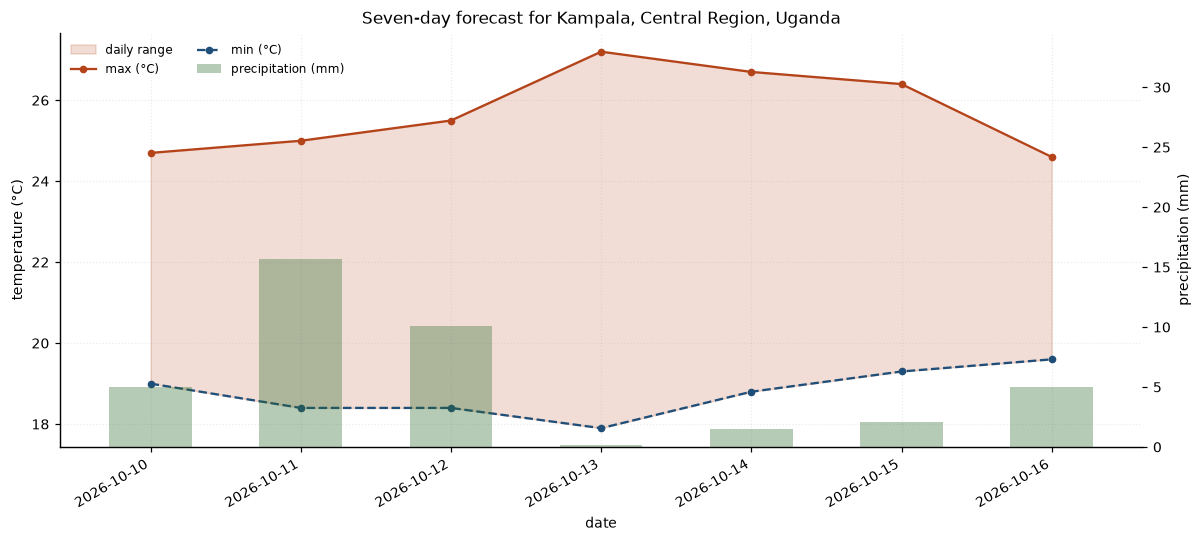

In [14]:
figure = plot_forecast(forecast, PLACE.label)
print("saved:", save(figure, "mp1_forecast.png").name)
plt.show()

---
# Part C: Robustness and a second source

## C1. Every request goes through one guarded function

`ApiClient.get_json` sets a timeout, calls `raise_for_status()`, retries
transient failures with exponential backoff up to a cap, and raises a
specific exception when it finally gives up. The backoff schedule is a pure
function of the policy, so it can be inspected without making a request.

In [15]:
policy = RetryPolicy(attempts=4, base_seconds=0.5, factor=2.0, ceiling_seconds=4.0)
print(f"policy  : {policy}")
print(f"delays  : {policy.delays()} seconds between attempts")
print(f"worst case spent waiting: {policy.total_wait()} s")
print()
print("the distinction that matters:")
print("  5xx / 429 / timeout  -> retry, the condition may clear")
print("  4xx                  -> do not retry, the request itself is wrong")

policy  : RetryPolicy(attempts=4, base_seconds=0.5, factor=2.0, ceiling_seconds=4.0)
delays  : [0.5, 1.0, 2.0] seconds between attempts
worst case spent waiting: 3.5 s

the distinction that matters:
  5xx / 429 / timeout  -> retry, the condition may clear
  4xx                  -> do not retry, the request itself is wrong


## C2. Four deliberately broken inputs

Each one is demonstrated rather than described.

In [16]:
print("1. an invalid city name")
try:
    geocode("Zzzqqxyznowhere", CLIENT)
except LocationNotFoundError as problem:
    print(f"   {type(problem).__name__}: {problem}")

1. an invalid city name
   LocationNotFoundError: no location matched 'Zzzqqxyznowhere'


In [17]:
print("2. an invalid latitude")
print("   (a) caught locally, before any request is made:")
try:
    get_forecast(999, 32.0, 7, CLIENT)
except ValueError as problem:
    print(f"       ValueError: {problem}")

print("   (b) and as the API itself rejects it — a recorded 400:")
try:
    OFFLINE.load("forecast_invalid_latitude")
except InvalidRequestError as problem:
    print(f"       {type(problem).__name__}: {problem}")
    print(f"       status {problem.status}, and it was NOT retried")

2. an invalid latitude
   (a) caught locally, before any request is made:
       ValueError: latitude 999 is outside -90..90
   (b) and as the API itself rejects it — a recorded 400:
       InvalidRequestError: https://api.open-meteo.com/v1/forecast?latitude=999&longitude=32.5&daily=weather_code%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=auto returned 400: Latitude must be in range of -90 to 90°. Given: 999.0.
       status 400, and it was NOT retried


In [18]:
print("3. no network (simulated by pointing at an unroutable host)")
broken = ApiClient("demo@example.ac.ug", timeout=2.0,
                   policy=RetryPolicy(attempts=3, base_seconds=0.05))
started = time.perf_counter()
try:
    broken.get_json("https://10.255.255.1/forecast")
except UpstreamUnavailableError as problem:
    print(f"   {type(problem).__name__}: {problem}")
    print(f"   gave up after {problem.attempts} attempts in "
          f"{(time.perf_counter() - started):.1f} s")

3. no network (simulated by pointing at an unroutable host)
   UpstreamUnavailableError: https://10.255.255.1/forecast did not respond after 3 attempt(s): ConnectTimeout: HTTPSConnectionPool(host='10.255.255.1', port=443): Max retries exceeded with url: /forecast (Caused by ConnectTimeoutError(<HTTPSConnection(host='10.255.255.1', port=443) at 0x1ffb6c3d810>, 'Connection to 10.255.255.1 timed out. (connect timeout=2.0)'))
   gave up after 3 attempts in 6.2 s


In [19]:
print("4. a timeout so small no response can arrive")
impatient = ApiClient(CONTACT_EMAIL if CONTACT_IS_REAL else "demo@example.ac.ug",
                      timeout=0.001,
                      policy=RetryPolicy(attempts=2, base_seconds=0.05))
try:
    impatient.get_json(GEOCODE_URL, {"name": "Kampala", "count": 1})
    print("   unexpectedly succeeded — the network was very fast")
except UpstreamUnavailableError as problem:
    print(f"   {type(problem).__name__}: {problem}")
    print(f"   underlying cause: {type(problem.last_error).__name__}")

4. a timeout so small no response can arrive
   UpstreamUnavailableError: https://geocoding-api.open-meteo.com/v1/search did not respond after 2 attempt(s): ConnectTimeout: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Kampala&count=1 (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 0x1ffb6c3e5d0>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=0.001)'))
   underlying cause: ConnectTimeout


## C3. The second source: MET Norway

Open-Meteo publishes daily aggregates. MET Norway publishes an **hourly**
timeseries, so the daily figures have to be built here: max and min of the
hourly air temperature, the sum of the six-hourly precipitation blocks taken
every sixth hour to avoid double-counting overlapping windows, and the
maximum hourly wind speed. MET Norway reports wind in **m/s**, which is
converted to km/h so the two tables are comparable — a unit mistake here
would make the second source look wildly wrong and the first look vindicated.

In [20]:
try:
    second, met_envelope = MetNoSource(CLIENT).daily(
        PLACE.latitude, PLACE.longitude, FORECAST_DAYS)
    print(f"MET Norway responded: {met_envelope!r}")
except (WeatherError, Exception) as problem:
    print(f"live MET Norway call unavailable ({type(problem).__name__}); "
          f"replaying the recording")
    second, met_envelope = MetNoSource(OFFLINE).daily(
        PLACE.latitude, PLACE.longitude, FORECAST_DAYS)

second

MET Norway responded: Envelope(200, 1023 ms, replayed, attempts=1)


,date,t_max_c,t_min_c,precip_mm,wind_max_kmh,weather_code,conditions
0,2026-10-10,24.8,18.6,6.7,13.7,None,not reported by MET Norway
1,2026-10-11,24.9,18.8,8.6,15.5,None,not reported by MET Norway
2,2026-10-12,25.2,18.5,9.2,14.8,None,not reported by MET Norway
3,2026-10-13,25.1,18.6,3.9,10.4,None,not reported by MET Norway
4,2026-10-14,26.4,19.8,0.9,9.0,None,not reported by MET Norway
5,2026-10-15,23.2,19.6,10.3,11.5,None,not reported by MET Norway
6,2026-10-16,25.8,19.7,7.7,14.0,None,not reported by MET Norway


In [21]:
agreement = compare_sources(forecast, second)
agreement[[c for c in agreement.columns if "max °C" in c or "rain" in c]]

,max °C (Open-Meteo),max °C (MET Norway),max °C Δ,rain mm (Open-Meteo),rain mm (MET Norway),rain mm Δ
date,,,,,,
2026-10-10,24.7,24.8,-0.1,5.0,6.7,-1.7
2026-10-11,25.0,24.9,0.1,15.7,8.6,7.1
2026-10-12,25.5,25.2,0.3,10.1,9.2,0.9
2026-10-13,27.2,25.1,2.1,0.2,3.9,-3.7
2026-10-14,26.7,26.4,0.3,1.5,0.9,0.6
2026-10-15,26.4,23.2,3.2,2.1,10.3,-8.2
2026-10-16,24.6,25.8,-1.2,5.0,7.7,-2.7


In [22]:
delta_t = agreement["max °C Δ"]
delta_rain = agreement["rain mm Δ"]
print(f"daily maximum temperature: the two models differ by "
      f"{delta_t.abs().mean():.2f} °C on average, "
      f"at most {delta_t.abs().max():.2f} °C")
print(f"precipitation:             they differ by "
      f"{delta_rain.abs().mean():.2f} mm on average, "
      f"at most {delta_rain.abs().max():.2f} mm")
print()
print("Temperature agreement is close; precipitation agreement is not, and")
print("that is the expected result rather than a bug. Temperature is a smooth")
print("field that both models resolve well. Rainfall in the tropics is")
print("convective and sub-grid: it depends on where an individual storm cell")
print("forms, which neither model can place. The daily totals also come from")
print("different aggregations — Open-Meteo sums its own daily field, while the")
print("MET Norway figure is rebuilt here from six-hourly blocks.")

daily maximum temperature: the two models differ by 1.04 °C on average, at most 3.20 °C
precipitation:             they differ by 3.56 mm on average, at most 8.20 mm

Temperature agreement is close; precipitation agreement is not, and
that is the expected result rather than a bug. Temperature is a smooth
field that both models resolve well. Rainfall in the tropics is
convective and sub-grid: it depends on where an individual storm cell
forms, which neither model can place. The daily totals also come from
different aggregations — Open-Meteo sums its own daily field, while the
MET Norway figure is rebuilt here from six-hourly blocks.


saved: mp1_source_agreement.png


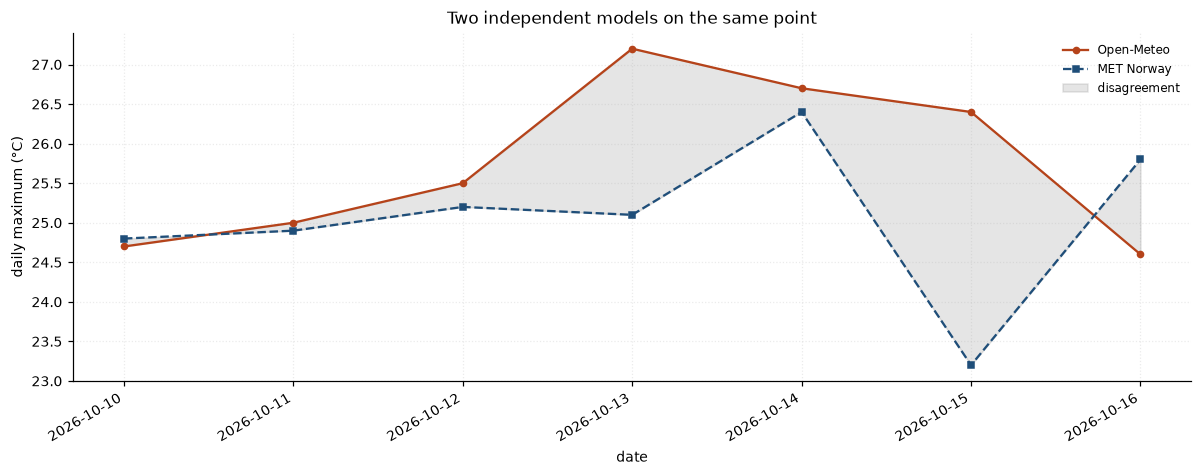

In [23]:
figure = plot_agreement(agreement)
print("saved:", save(figure, "mp1_source_agreement.png").name)
plt.show()

---
# Part D: Report

## The data flow, from a typed name to a displayed forecast

```
  LOCATION = "Kampala"            CONTACT_EMAIL (env var or config cell)
       |                                   |
       v                                   v
  +-------------------+          +---------------------------+
  |  geocode(name)    |          |  User-Agent construction  |
  +-------------------+          +---------------------------+
       |                                   |
       |  GET geocoding-api/v1/search      |
       +-----------------------------------+
       |
       v
  +---------------------------------------------+
  |  ApiClient.get_json: timeout, raise_for_     |
  |  status, exponential backoff, retry cap      |-- fails --> UpstreamUnavailableError
  +---------------------------------------------+
       |                               ^
       v                               |  (offline / no contact)
  +-------------------+         +--------------------+
  |  parse_places()   |         |   ReplayClient     |
  +-------------------+         |  data/samples/*.json|
       |                        +--------------------+
       |  zero results? -> LocationNotFoundError
       |  many results? -> AmbiguousLocationError -> choose_place()
       v
  +-------------------+
  |  Place (lat, lon) |
  +-------------------+
       |
       v
  +---------------------------+     +---------------------------+
  | OpenMeteoSource.daily()   |     |  MetNoSource.daily()      |
  | daily aggregates          |     |  hourly -> rolled to daily|
  +---------------------------+     +---------------------------+
       |                                   |
       v                                   v
  +---------------------------------------------+
  |  parse_*_daily() -> pandas DataFrame         |
  |  + WMO code decoded to a description         |
  +---------------------------------------------+
       |
       +--------------------+-------------------+
       v                    v                   v
  summarise()         format_table()      plot_forecast()
  (text)              (table)             (chart)
```

The shape worth noticing is that **parsing is separated from fetching**.
`parse_places` and `parse_open_meteo_daily` are pure functions over a
dictionary; they never touch the network. That is what allows the whole test
suite to run offline against recorded payloads, and it is where the real
defects live — the `results`-key trap is a parsing bug, not a networking one.

## Licensing and usage terms, and what they mean for a real product

**Open-Meteo** publishes its data under CC BY 4.0 and its API is free for
non-commercial use without a key, with commercial use requiring a paid plan.
CC BY carries an attribution obligation: a product built on this data has to
say so visibly, which is why `OpenMeteoSource.attribution` is a property of
the class instead of a comment. The free tier is rate-limited by fair use
rather than a hard quota, which is comfortable for coursework and unsuitable
for anything with real traffic — a product would need the commercial plan,
and would need it *before* launch, since migrating later means a second
integration under deadline.

**MET Norway** publishes Locationforecast 2.0 under CC BY 4.0 and the
Norwegian Licence for Open Government Data. Their terms are stricter in one
specific way: they require an identifying `User-Agent` with genuine contact
details and will block clients that do not supply one, they ask that clients
respect the `Expires` header and the `If-Modified-Since` mechanism rather
than polling, and they cap throughput at roughly 20 requests per second. The
contact requirement is the reason this notebook refuses to make live MET
Norway calls until a real address is configured: inventing one would breach
the terms, and the brief says the same thing.

For a real product the practical consequences are three. Attribution must
appear in the user interface, not buried in a licence file. Caching is not an
optimisation but a condition of use — MET Norway's `Expires` header tells you
exactly how long a response stays valid, and ignoring it while scaling is how
an application gets blocked. And depending on a free tier is a commercial
risk: both providers can change terms, and a product with no fallback source
has a single point of failure that is contractual and not technical.

## Reliability issues met, and how the code handles them

Four distinct problems appeared while building this, and each shaped the
code.

**The missing `results` key.** Searching for a name that matches nothing
returns HTTP 200 with a body containing only `generationtime_ms`. There is no
empty list and no error flag. Code written as `payload["results"]` raises
`KeyError` — not where the request is made, but later, wherever the payload
is finally read. `parse_places` uses `.get("results")` and raises
`LocationNotFoundError`, which names the problem at the point it occurs.

**TLS verification differing between libraries.** The MET Norway endpoint
failed through `urllib` with `CERTIFICATE_VERIFY_FAILED` while succeeding
through `requests` on the same machine. `requests` bundles the `certifi` CA
set; `urllib` trusts the platform store, which on this installation lacked
the issuer. The practical lesson is that "the API is down" and "my HTTP
library cannot verify it" look identical from the call site, and only trying
a second client distinguishes them.

**Transient versus permanent failure.** A 503 may clear in a second; a 400 on
an out-of-range latitude will not. Retrying the second wastes four round
trips and delays the error the user needs to see. `ApiClient` separates them:
`RETRYABLE_STATUS` lists the codes worth repeating, and a 4xx raises
`InvalidRequestError` immediately, carrying the provider's own `reason`
string.

**Unbounded waiting.** Exponential backoff without a cap can leave a
notebook apparently hung. `RetryPolicy` caps each delay at
`ceiling_seconds` and the total attempts at `attempts`, and
`total_wait()` reports the worst case up front, so the maximum time a cell
can block is knowable before it is run.

## Privacy implications of sending location queries to third parties

A geocoding request is not neutral telemetry. The query string carries a
place name, the request carries an IP address, and the `User-Agent` built
here carries an email address. Together those three fields link an
identifiable person to an expressed interest in a specific place at a
specific time, held by a third party in another jurisdiction.

The provider's side of this is reasonable: MET Norway asks for contact
details precisely so it can reach operators of misbehaving clients, which is
a legitimate operational need. But the effect is that the identifier is
attached to every request, including ones where it serves no purpose.
Open-Meteo requires no such header, so this client sends the same contact to
a provider that did not ask for it — something a production client should
narrow rather than apply uniformly.

The sharper issue is aggregation. One query for "Kampala" reveals almost
nothing. A user's full query history over months reveals where they live,
when they travel, and where they are heading next; and because forecast
requests carry precise coordinates instead of a name, a product that
geocodes the user's own position is transmitting their location trail to an
external service in clear form. Neither provider is doing anything improper
with it, but the data is leaving the user's control either way.

Three mitigations follow directly and are cheap. **Round the coordinates**
before sending: this notebook passes four decimal places to MET Norway
(roughly 10 m), which is far more precision than a forecast needs — two
decimals, about 1 km, would be ample and would meaningfully degrade the
trail. **Cache aggressively**, which reduces both the request volume and the
resolution of the timing data a provider can observe. And **keep the contact
address out of the repository**, which is why it is read from an environment
variable here: committing it would publish a personal identifier to everyone
with repository access, permanently, in the git history where deleting it
later does not actually remove it.

A final point specific to coursework: the recorded responses in
`data/samples/` contain no personal data, only public forecast values, which
is why they are safe to commit. The same would not be true of a log of real
user queries, and a project that recorded those for offline testing would
have created a privacy problem in the act of trying to be reproducible.

## Offline checks

The brief asks for at least five assert-based checks on the parsing
functions, running against saved sample JSON. The full suite lives in
`tests/test_weather.py` (53 tests); the cell below runs a representative
handful inline so this notebook demonstrates them directly.

In [24]:
from src.weather.sources import parse_metno_daily, parse_open_meteo_daily, parse_places

samples = {stem: OFFLINE.load(stem).payload
           for stem in ("geocode_kampala", "geocode_zero_results",
                        "forecast_kampala", "metno_kampala")}

# 1. a good geocoding payload parses to usable coordinates
places = parse_places(samples["geocode_kampala"], "Kampala")
assert places and places[0].country == "Uganda"
assert -90 <= places[0].latitude <= 90

# 2. a zero-result payload raises rather than throwing KeyError
assert "results" not in samples["geocode_zero_results"]
try:
    parse_places(samples["geocode_zero_results"], "nowhere")
    raise AssertionError("should have raised")
except LocationNotFoundError:
    pass

# 3. the forecast table has the expected columns and sane values
table = parse_open_meteo_daily(samples["forecast_kampala"])
assert len(table) == 7
assert (table["t_max_c"] >= table["t_min_c"]).all()
assert (table["precip_mm"] >= 0).all()

# 4. weather codes decode, and an unknown one does not silently become "clear"
assert describe(95) == "Thunderstorm"
assert "Unknown" in describe(7) or "code 7" in describe(7)

# 5. MET Norway's hourly data rolls up to the same shape, in km/h
rolled = parse_metno_daily(samples["metno_kampala"], days=7)
assert list(rolled.columns) == list(table.columns)
assert (rolled["t_max_c"] >= rolled["t_min_c"]).all()

# 6. and the two sources broadly agree on temperature
assert compare_sources(table, rolled)["max °C Δ"].abs().max() < 5.0

print("all six inline checks passed, using only recorded sample JSON")
print(f"the full suite in tests/ runs {len(available_samples())} recorded "
      f"responses through 53 tests, with no network")

all six inline checks passed, using only recorded sample JSON
the full suite in tests/ runs 16 recorded responses through 53 tests, with no network
